<a href="https://colab.research.google.com/github/TasminaTasin75/binary-classification-mnist-dataset/blob/main/ml_assignment_build_analyze_binary_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
import os

DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/ML-Assignment-MNIST/dataset/mnist_1_7_subsets-1.npz"

print("Does Dataset exists? :", os.path.exists(DATASET_PATH))


Does Dataset exists? : True


In [5]:
# Loading the dataset
import numpy as np

data = np.load(DATASET_PATH)

print(data)

NpzFile '/content/drive/MyDrive/Colab Notebooks/ML-Assignment-MNIST/dataset/mnist_1_7_subsets-1.npz' with keys: train_data, train_targets, test_data, test_targets


In [13]:
#Accessing the available arrays
X_train = data["train_data"]
y_train = data["train_targets"]

X_test = data["test_data"]
y_test = data["test_targets"]

# checking the shapes

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)


Training images: (100, 28, 28)
Training labels: (100,)
Test images: (1000, 28, 28)
Test labels: (1000,)


Looking inside the dataset

In [14]:
# Data types
print("Data types:")
print("Training images:", X_train.dtype)
print("Training labels:", y_train.dtype)
print("Test images:", X_test.dtype)
print("Test labels:", y_test.dtype)

Data types:
Training images: uint8
Training labels: int64
Test images: uint8
Test labels: int64


In [15]:
# Labels
print("Training labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))

Training labels: [1 7]
Test labels: [1 7]


Checking the Class balance to see the number of images of digit 1 and 7 exist in each dataset

In [16]:
train_labels, train_counts = np.unique(
    y_train, return_counts=True
)

test_labels, test_counts = np.unique(
    y_test, return_counts=True
)

print("Training set class distribution:")
for label, count in zip(train_labels, train_counts):
    percentage = count / len(y_train) * 100
    print(f"Digit {label}: {count} images  - {percentage:.2f}%")

print("Test set class distribution:")
for label, count in zip(test_labels, test_counts):
    percentage = count / len(y_test) * 100
    print(f"Digit {label}: {count} images  - {percentage:.2f}%")


Training set class distribution:
Digit 1: 50 images  - 50.00%
Digit 7: 50 images  - 50.00%
Test set class distribution:
Digit 1: 100 images  - 10.00%
Digit 7: 900 images  - 90.00%


Check for missing values in train data

In [17]:
missing_val = np.isnan(X_train).sum()
print("Missing values in training images:", missing_val)

Missing values in training images: 0


Pixel Intensity Stats

In [19]:
# Pixel intensity range
print("Training pixel intensity:")
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())
print("Mean:", round(X_train.mean(), 2))
print("Standard deviation:", round(X_train.std(), 2))


print("\nTest pixel intensity:")
print("Minimum:", X_test.min())
print("Maximum:", X_test.max())

Training pixel intensity:
Minimum: 0
Maximum: 255
Mean: 24.85
Standard deviation: 69.69

Test pixel intensity:
Minimum: 0
Maximum: 255


Pixel intensity Stats for each digit

In [32]:
print("Pixel statistics for each digit:")

for digit in [1, 7]:
    digit_images = X_train[y_train == digit]

    print(f"\nDigit {digit}:")
    print("Number of images:", len(digit_images))
    print("Mean pixel intensity:", round(digit_images.mean(), 2))
    print("Pixel intensity standard deviation:", round(digit_images.std(), 2))

Pixel statistics for each digit:

Digit 1:
Number of images: 50
Mean pixel intensity: 20.18
Pixel intensity standard deviation: 63.75

Digit 7:
Number of images: 50
Mean pixel intensity: 29.53
Pixel intensity standard deviation: 74.88


Visualizing the sample images (5 images of Digit 1 and 5 images of digit 7)

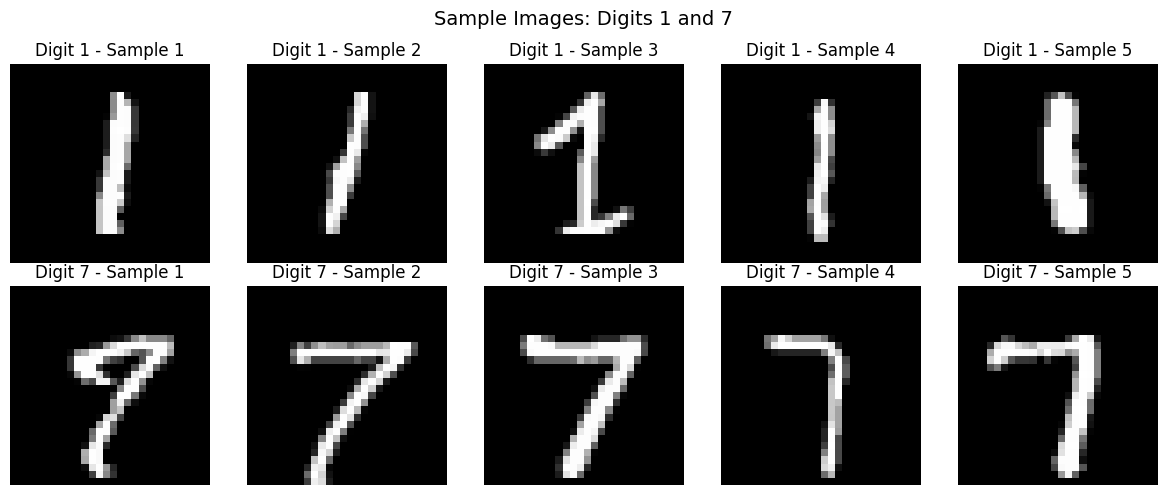

In [34]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Displaying 5 samples of each digit
for row, digit in enumerate([1, 7]):
    digit_images = X_train[y_train == digit]

    for col in range(5):
        axes[row, col].imshow(digit_images[col], cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"Digit {digit} - Sample {col + 1}")
        axes[row, col].axis("off")

plt.suptitle("Sample Images: Digits 1 and 7", fontsize=14)
plt.tight_layout()
plt.show()
